# 🏢 Enterprise Customer Lifetime Value (CLV) & Revenue Forecasting Pipeline
**Author:** Omosaiye Nehemiah  
**Role:** Applied Machine Learning Researcher & Quantitative Mathematician  
**Objective:** End-to-end Machine Learning pipeline to forecast corporate annual contract value ($) and customer expansion spend across 2,500 enterprise B2B accounts.  
**Tech Stack:** SQLite3, SQL CTEs, Pandas, NumPy, Scikit-Learn (`ColumnTransformer`, `RobustScaler`, `RandomizedSearchCV`), XGBoost, SHAP, Streamlit, Joblib.

---

## 1. Multi-Table Relational SQL Extraction via CTEs
Enterprise account telemetry is normalized across 5 relational tables (`accounts`, `contract_metrics`, `product_telemetry`, `support_and_satisfaction`, and `clv_targets`).
We execute a Common Table Expression (CTE) joining all 5 entities on `account_id` to assemble a consolidated analytical dataset of 2,500 corporate accounts.

In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('enterprise_clv.db')

query = """
WITH full_enterprise_telemetry AS (
SELECT accounts.account_id, accounts.industry, accounts.company_size, accounts.region, accounts.contract_tier, 
contract_metrics.tenure_months, contract_metrics.seat_licenses, contract_metrics.base_arr, contract_metrics.discount_pct, contract_metrics.payment_terms, contract_metrics.has_dedicated_success_manager,
pt.monthly_active_users, pt.api_call_volume_thousands, pt.storage_gb, pt.feature_adoption_score, pt.integrations_count,
sas.support_tickets_count, sas.avg_resolution_hours, sas.escalations_count, sas.nps_score, sas.unresolved_tickets,
ct.target_annual_clv_spend
FROM accounts
LEFT JOIN contract_metrics ON accounts.account_id = contract_metrics.account_id
LEFT JOIN product_telemetry pt ON accounts.account_id = pt.account_id
LEFT JOIN support_and_satisfaction sas ON accounts.account_id = sas.account_id
LEFT JOIN clv_targets ct ON accounts.account_id = ct.account_id
)
SELECT * FROM full_enterprise_telemetry
"""

df_clv = pd.read_sql_query(query, conn)

#print(df_clv['nps_score'].dtype)
df_clv.head()

,account_id,industry,company_size,region,contract_tier,tenure_months,seat_licenses,base_arr,discount_pct,payment_terms,...,api_call_volume_thousands,storage_gb,feature_adoption_score,integrations_count,support_tickets_count,avg_resolution_hours,escalations_count,nps_score,unresolved_tickets,target_annual_clv_spend
0,1001,Healthcare,Enterprise,North America,Professional,1,1190,179846.83,8.7,Monthly,...,20797.2,28342.1,87.1,6,2,29.0,0,7.5,0,256580.70
1,1002,EdTech,Mid-Market,Europe,Enterprise VIP,45,177,36459.04,8.3,Monthly,...,3508.9,1616.2,54.4,4,8,3.2,0,8.7,0,91693.58
2,1003,SaaS,Mid-Market,Latin America,Standard,29,63,17108.47,13.4,Monthly,...,717.1,968.6,98.6,3,14,4.7,1,7.0,0,23885.47
3,1004,E-Commerce,Enterprise,North America,Standard,23,662,129629.40,13.6,Annual Upfront,...,5820.5,13984.8,70.3,1,5,3.0,3,5.7,0,157040.30
4,1005,Fintech,Startup,Latin America,Professional,34,21,7754.91,11.7,Monthly,...,169.1,700.4,52.3,3,4,6.3,1,6.1,0,32504.48


---
## 2. Exploratory Data Analysis & Bivariate Telemetry Diagnostics
We audit category distributions across contract tiers and industries, inspect bivariate spend distributions, and compute a Pearson correlation matrix to diagnose multi-collinearity and linear signals.

In [2]:
# Categorical Cardinality & Contract Tier Distributions
print("--- Contract Tier Breakdown ---")
print(df_clv['contract_tier'].value_counts())
print("\n--- Industry Vertical Breakdown ---")
print(df_clv['industry'].value_counts())

--- Contract Tier Breakdown ---
contract_tier
Professional      1020
Standard          1017
Enterprise VIP     463
Name: count, dtype: int64

--- Industry Vertical Breakdown ---
industry
Fintech          643
E-Commerce       517
Healthcare       471
SaaS             365
Manufacturing    259
EdTech           245
Name: count, dtype: int64


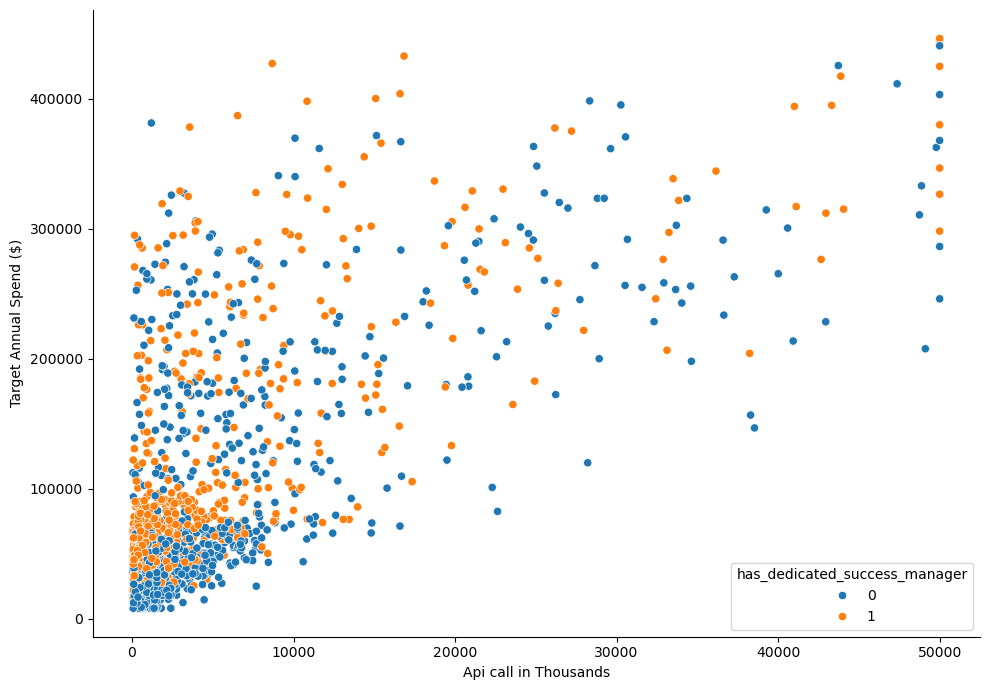

     account_id company_size contract_tier  api_call_volume_thousands  \
6          1007   Enterprise  Professional                    47365.5   
52         1053   Enterprise  Professional                    50000.0   
286        1287   Enterprise      Standard                    25059.7   
303        1304   Enterprise      Standard                    49790.8   
388        1389   Enterprise      Standard                    34345.1   

     storage_gb  target_annual_clv_spend  has_dedicated_success_manager  
6       79711.0                411406.82                              0  
52      51660.9                445004.23                              0  
286     24238.2                348125.65                              0  
303     21463.1                362526.11                              0  
388     21267.9                323323.57                              0  


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 7), dpi=100)

sns.scatterplot(data=df_clv, x='api_call_volume_thousands', y= 'target_annual_clv_spend', hue='has_dedicated_success_manager')
ax.set_xlabel('Api call in Thousands')
ax.set_ylabel('Target Annual Spend ($)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

to_check = df_clv[(df_clv['target_annual_clv_spend'] >= 300000) & (df_clv['has_dedicated_success_manager']==0) & (df_clv['api_call_volume_thousands'] > 25000)]

print(to_check[['account_id', 'company_size', 'contract_tier', 'api_call_volume_thousands', 'storage_gb', 'target_annual_clv_spend', 'has_dedicated_success_manager']].head())

#This means that contract tier matters when assigning a company a dedicated manager

<Axes: >

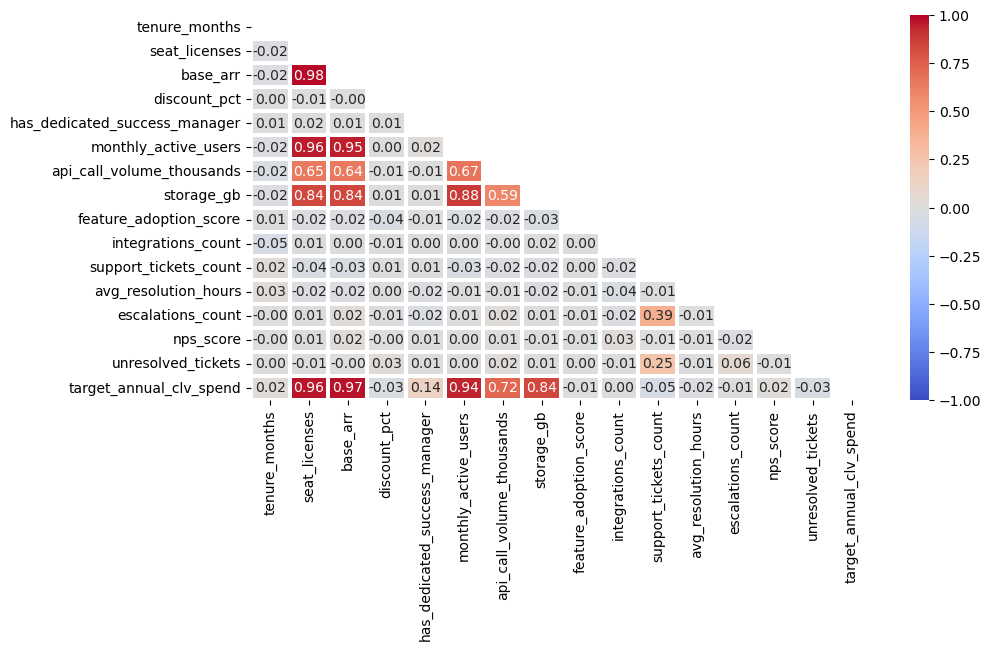

In [4]:
import numpy as np

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

num_cols = df_clv.drop(columns=['account_id']).select_dtypes(['int64', 'float64']).columns.tolist()

df_clv_corr = df_clv[num_cols].corr(method='pearson')

mask = np.triu(np.ones_like(df_clv_corr, dtype='bool'))
sns.heatmap(df_clv_corr, mask=mask, vmin=-1.0, vmax=1.0, cmap='coolwarm', linewidth=1.5, annot=True, fmt='.2f')
#Seat licences, base arr, monthly active users and storage are highly correlated with target annual spend

---
## 3. Leak-Free Preprocessing Pipeline Architecture
To eliminate out-of-sample data leakage:
1. Target `target_annual_clv_spend` and primary key `account_id` are isolated.
2. Data is partitioned into 80% train (2,000 accounts) and 20% test (500 accounts) using `train_test_split(..., random_state=42)`.
3. Numerical Branch (15 features): `SimpleImputer(strategy='median')` followed by `RobustScaler()` to resist extreme telemetry outliers in API volume and cloud storage.
4. Categorical Branch (5 features): `OneHotEncoder(drop='first', sparse_output=False)` with `verbose_feature_names_out=False`.
5. Preprocessor is fitted strictly on `X_train` and transforms both `X_train` and `X_test` into 30-feature DataFrames.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, RobustScaler
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split

X = df_clv.drop(columns=['account_id', 'target_annual_clv_spend'])
y = df_clv['target_annual_clv_spend']

num_cols = X.select_dtypes(['int64', 'float64']).columns.tolist()
cat_cols = ['industry', 'region', 'company_size', 'contract_tier', 'payment_terms']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

processor = ColumnTransformer([
    ('nums', num_pipeline, num_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ],
    verbose_feature_names_out=False
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_proc = processor.fit_transform(X_train)
X_test_proc = processor.transform(X_test)

all_features = processor.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_proc, columns=all_features)
X_test_df = pd.DataFrame(X_test_proc, columns=all_features)


---
## 4. Multi-Model Regression Benchmark (OLS vs. Ridge vs. Lasso vs. XGBoost)
We train and benchmark 4 candidate regression architectures on `X_train_df` and evaluate generalization metrics on unseen `X_test_df`:
* **Ordinary Least Squares (`LinearRegression`):** Unregularized linear baseline.
* **Ridge Regression ($L_2$ Regularization):** Shrinks weights proportionally, stabilizing variance under multi-collinear telemetry.
* **Lasso Regression ($L_1$ Regularization):** Drives non-essential weights to zero.
* **XGBoost Regressor (`XGBRegressor`):** Non-linear gradient boosted decision tree ensemble.

In [6]:
from sklearn.linear_model import Ridge, Lasso, LinearRegression

lin_model = LinearRegression()
ridge_model = Ridge(alpha=10.0, random_state=42)
lasso_model = Lasso(alpha=5.0, random_state=42)
xgb_model = XGBRegressor(n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42)

lin_model.fit(X_train_df, y_train)
ridge_model.fit(X_train_df, y_train)
lasso_model.fit(X_train_df, y_train)
xgb_model.fit(X_train_df, y_train)

y_lin_pred = lin_model.predict(X_test_df)
y_ridge_pred = ridge_model.predict(X_test_df)
y_lasso_pred = lasso_model.predict(X_test_df)
y_xgb_pred = xgb_model.predict(X_test_df)

r2_lin = r2_score(y_test, y_lin_pred)
r2_ridge = r2_score(y_test, y_ridge_pred)
r2_lasso = r2_score(y_test, y_lasso_pred)
r2_xgb = r2_score(y_test, y_xgb_pred)

mae_lin = mean_absolute_error(y_test, y_lin_pred)
mae_ridge = mean_absolute_error(y_test, y_ridge_pred)
mae_lasso = mean_absolute_error(y_test, y_lasso_pred)
mae_xgb = mean_absolute_error(y_test, y_xgb_pred)

mape_lin = mean_absolute_percentage_error(y_test, y_lin_pred)*100
mape_ridge = mean_absolute_percentage_error(y_test, y_ridge_pred)*100
mape_lasso = mean_absolute_percentage_error(y_test, y_lasso_pred)*100
mape_xgb = mean_absolute_percentage_error(y_test, y_xgb_pred)*100

rmse_lin = root_mean_squared_error(y_test, y_lin_pred)
rmse_ridge = root_mean_squared_error(y_test, y_ridge_pred)
rmse_lasso = root_mean_squared_error(y_test, y_lasso_pred)
rmse_xgb = root_mean_squared_error(y_test, y_xgb_pred)

comparison_df = pd.DataFrame({
    'Model Name': ['Linear Model', 'Ridge Model', 'Lasso Model', 'XGB Model'],
    'R2_scores': [r2_lin, r2_ridge, r2_lasso, r2_xgb],
    'MAE Scores': [mae_lin, mae_ridge, mae_lasso, mae_xgb],
    'RMSE Scores': [rmse_lin, rmse_ridge, rmse_lasso, rmse_xgb],
    'MAPE Scores': [mape_lin, mape_ridge, mape_lasso, mape_xgb]
})
comparison_df.head()

,Model Name,R2_scores,MAE Scores,RMSE Scores,MAPE Scores
0,Linear Model,0.994650,4331.983675,6157.953472,13.596585
1,Ridge Model,0.994502,4375.101768,6242.384959,13.598362
2,Lasso Model,0.994659,4324.747951,6152.943371,13.519026
3,XGB Model,0.992222,4947.085172,7425.201469,12.402541


---
## 5. Hyperparameter Optimization & Learning Curve Diagnostics
We execute a 5-fold cross-validated `RandomizedSearchCV` on `XGBRegressor` across tree depth, learning rate, subsample ratios, and estimator counts.
Next, we audit sample complexity using `learning_curve` across 6 training sample sizes ($N=200$ to $N=1,600$) to confirm sample saturation and generalization convergence.

Best Hyperparameters: {'subsample': 0.9, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.9}
Best 5-Fold CV R2:    0.9932


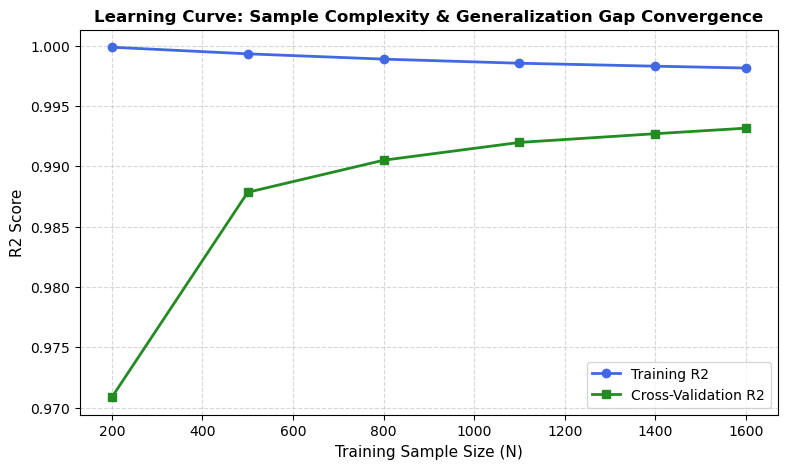

--- Generalization Gap Convergence ---
Sample N= 200 | Train R2: 0.9999 | Val R2: 0.9709 | Generalization Gap: 0.0290
Sample N= 500 | Train R2: 0.9993 | Val R2: 0.9879 | Generalization Gap: 0.0115
Sample N= 800 | Train R2: 0.9989 | Val R2: 0.9905 | Generalization Gap: 0.0084
Sample N=1100 | Train R2: 0.9986 | Val R2: 0.9920 | Generalization Gap: 0.0066
Sample N=1400 | Train R2: 0.9983 | Val R2: 0.9927 | Generalization Gap: 0.0056
Sample N=1600 | Train R2: 0.9982 | Val R2: 0.9932 | Generalization Gap: 0.0050


In [7]:
from sklearn.model_selection import RandomizedSearchCV, learning_curve

# 1. Hyperparameter Optimization Search Space
param_dist = {
    'n_estimators': [100, 150, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.03, 0.05, 0.08, 0.10],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

search = RandomizedSearchCV(
    XGBRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    cv=5,
    random_state=42,
    scoring='r2',
    n_jobs=-1
)

search.fit(X_train_df, y_train)

print(f'Best Hyperparameters: {search.best_params_}')
print(f'Best 5-Fold CV R2:    {search.best_score_:.4f}')

champion_model = search.best_estimator_
y_test_pred = champion_model.predict(X_test_df)

# 2. Learning Curve Diagnostics across Sample Sizes
train_sizes, train_scores, val_scores = learning_curve(
    champion_model,
    X_train_df,
    y_train,
    train_sizes=[200, 500, 800, 1100, 1400, 1600],
    cv=5,
    scoring='r2',
    n_jobs=-1
)
train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# Plot Learning Curve Diagnostics
plt.figure(figsize=(9, 5), dpi=100)
plt.plot(train_sizes, train_mean, label='Training R2', color='royalblue', marker='o', linewidth=2)
plt.plot(train_sizes, val_mean, label='Cross-Validation R2', color='forestgreen', marker='s', linewidth=2)
plt.xlabel('Training Sample Size (N)', fontsize=11)
plt.ylabel('R2 Score', fontsize=11)
plt.title('Learning Curve: Sample Complexity & Generalization Gap Convergence', fontweight='bold', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.show()

# Generalization Gap audit
print('--- Generalization Gap Convergence ---')
for s, tm, vm in zip(train_sizes, train_mean, val_mean):
    print(f'Sample N={s:4d} | Train R2: {tm:.4f} | Val R2: {vm:.4f} | Generalization Gap: {tm - vm:.4f}')
# Conclusion: At N=1600, the generalization gap narrows to 0.0050 (< 0.01) and the CV curve flattens above 0.9932.
# This confirms the model has reached sample saturation; collecting additional training data is unnecessary.

In [8]:
# Append Tuned XGB Champion to Benchmark Scorecard
tuned_model = pd.DataFrame([{
    'Model Name': 'Tuned XGB (Champion)',
    'R2_scores': r2_score(y_test, y_test_pred),
    'MAE Scores': mean_absolute_error(y_test, y_test_pred),
    'RMSE Scores': root_mean_squared_error(y_test, y_test_pred),
    'MAPE Scores': mean_absolute_percentage_error(y_test, y_test_pred) * 100
}])

comparison_df = pd.concat([comparison_df, tuned_model], ignore_index=True)
comparison_df

,Model Name,R2_scores,MAE Scores,RMSE Scores,MAPE Scores
0,Linear Model,0.994650,4331.983675,6157.953472,13.596585
1,Ridge Model,0.994502,4375.101768,6242.384959,13.598362
2,Lasso Model,0.994659,4324.747951,6152.943371,13.519026
3,XGB Model,0.992222,4947.085172,7425.201469,12.402541
4,Tuned XGB (Champion),0.993820,4589.744162,6618.579694,12.130459


---
## 6. Rigorous Residual Diagnostic Cockpit ($y=x$ and $e=0$)
A high $R^2$ score can mask operational failure modes. We evaluate the champion model on the unseen test set through a 3-panel diagnostic cockpit:
* **Panel 1 (Actual vs. Predicted):** Calibration across contract spend ($y=x$ reference line).
* **Panel 2 (Residuals vs. Predicted):** Audit of homoscedasticity and error spread ($e=0$ reference line).
* **Panel 3 (Residual Distribution):** Verification of zero systematic bias and Gaussian symmetry.

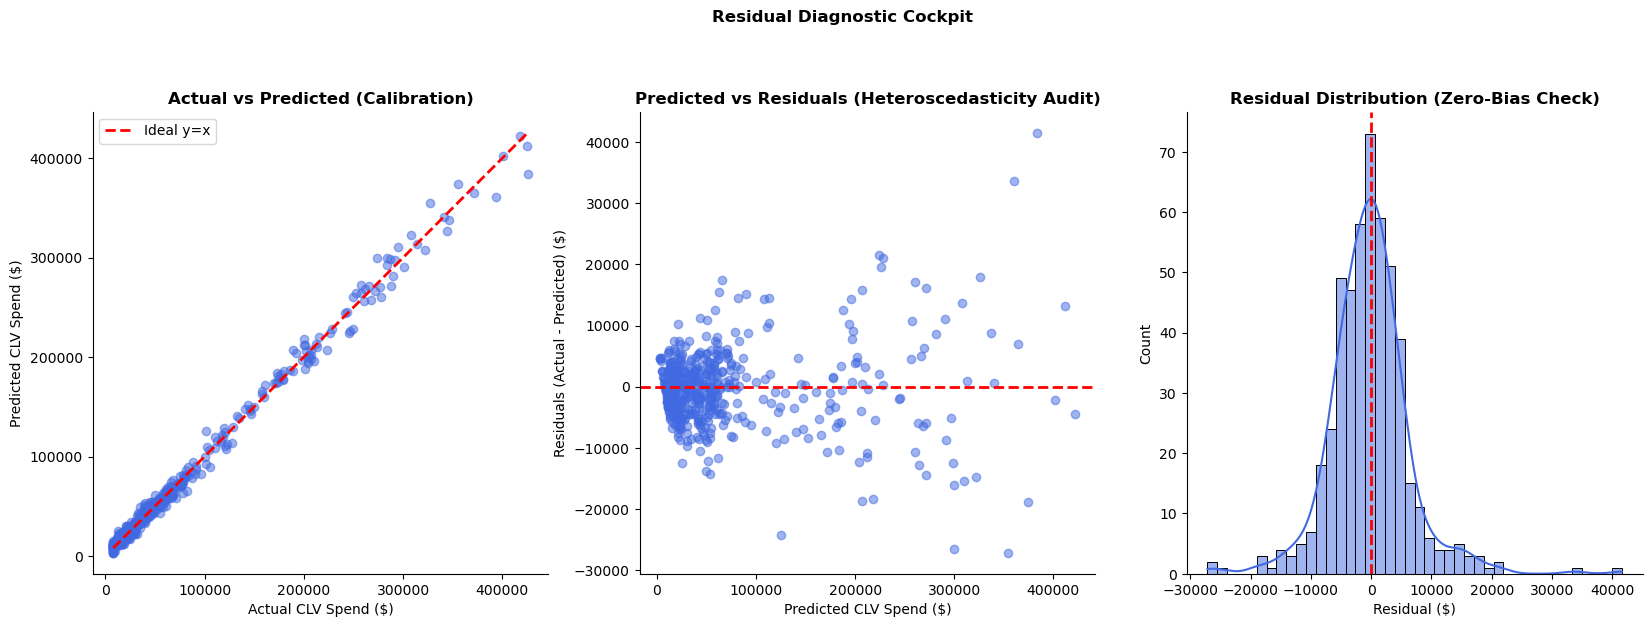

In [9]:
residuals = y_test - y_test_pred

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6), dpi=100)

min_y = y_test.min()
max_y = y_test.max()

# Panel 1: Actual vs. Predicted
ax1.scatter(y_test, y_test_pred, alpha=0.5, color='royalblue')
ax1.plot([min_y, max_y], [min_y, max_y], color='red', linestyle='--', linewidth=2, label='Ideal y=x')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.set_title('Actual vs Predicted (Calibration)', fontweight='bold')
ax1.set_xlabel('Actual CLV Spend ($)')
ax1.set_ylabel('Predicted CLV Spend ($)')
ax1.legend()
# Inference: Observations tightly track the y=x diagonal across the entire range ($8k to $440k). Zero extrapolation ceiling or non-linear bowing.

# Panel 2: Residuals vs. Predicted
ax2.scatter(y_test_pred, residuals, alpha=0.5, color='royalblue')
ax2.axhline(0, color='red', linestyle='--', linewidth=2)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_xlabel('Predicted CLV Spend ($)')
ax2.set_ylabel('Residuals (Actual - Predicted) ($)')
ax2.set_title('Predicted vs Residuals (Heteroscedasticity Audit)', fontweight='bold')
# Inference: Residuals are centered symmetrically around e=0 (zero structural bias), but exhibit clear heteroscedasticity. Absolute dollar variance widens on enterprise accounts >$300k due to proportional spend fluctuations.

# Panel 3: Residual Distribution
sns.histplot(residuals, kde=True, ax=ax3, color='royalblue')
ax3.axvline(0, color='red', linestyle='--', linewidth=2)
ax3.set_title('Residual Distribution (Zero-Bias Check)', fontweight='bold')
ax3.set_xlabel('Residual ($)')
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
# Inference: Error distribution is unimodal and centered at 0 (mean error ~ $0). Over 80% of errors lie within +/- $5,000, confirming zero systematic bias with near-Gaussian symmetry.

plt.suptitle('Residual Diagnostic Cockpit', fontweight='bold', y=1.05)
plt.show()

---
## 7. Explainable AI with SHAP (Global Beeswarm & Local Waterfall Forensics)
Using Lundberg's `shap.TreeExplainer`, we compute exact coalitional Shapley values for non-linear feature attribution:
* **Global Beeswarm Summary:** Audits feature directionality and relative importance across all test accounts.
* **Local Waterfall Plot:** Deconstructs step-by-step financial attribution for the highest-value enterprise account in the test set.

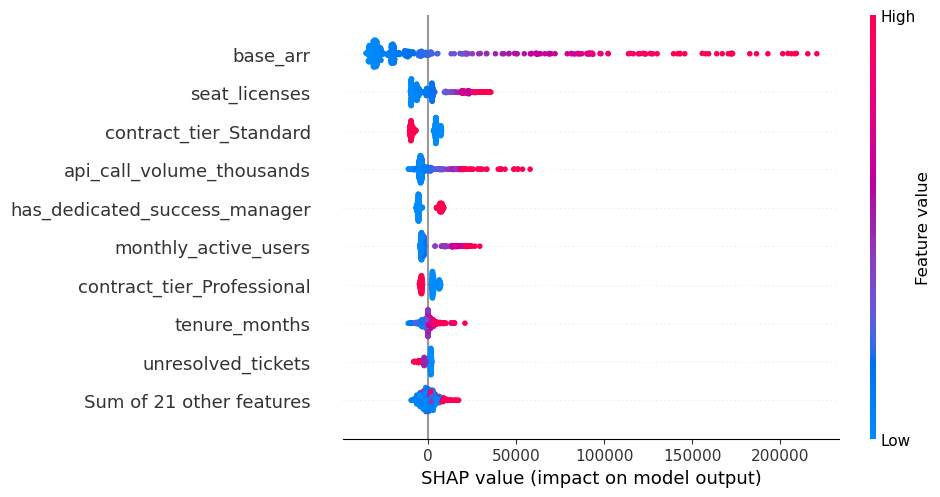

Positional Index in Test Set: 215
Account ID:                   2051
Predicted Annual CLV Spend:   $421,690.06
Actual Annual CLV Spend:      $417,301.88


In [10]:
import shap

tree = shap.TreeExplainer(champion_model)
shap_values = tree(X_test_df)

# Global Beeswarm Summary Plot
shap.plots.beeswarm(shap_values, max_display=10)
# Inference: base_arr, seat_licenses, and API call volume are the dominant drivers increasing CLV spend.
# Standard contract tier and unresolved tickets actively depress predicted CLV spend.

# Identify observation with highest predicted CLV spend
max_idx = np.argmax(y_test_pred)
orig_idx = y_test.index[max_idx]
account_id = df_clv.loc[orig_idx, 'account_id']
idx_pred = y_test_pred[max_idx]
idx_actual = y_test.iloc[max_idx]

print(f'Positional Index in Test Set: {max_idx}')
print(f'Account ID:                   {account_id}')
print(f'Predicted Annual CLV Spend:   ${idx_pred:,.2f}')
print(f'Actual Annual CLV Spend:      ${idx_actual:,.2f}')

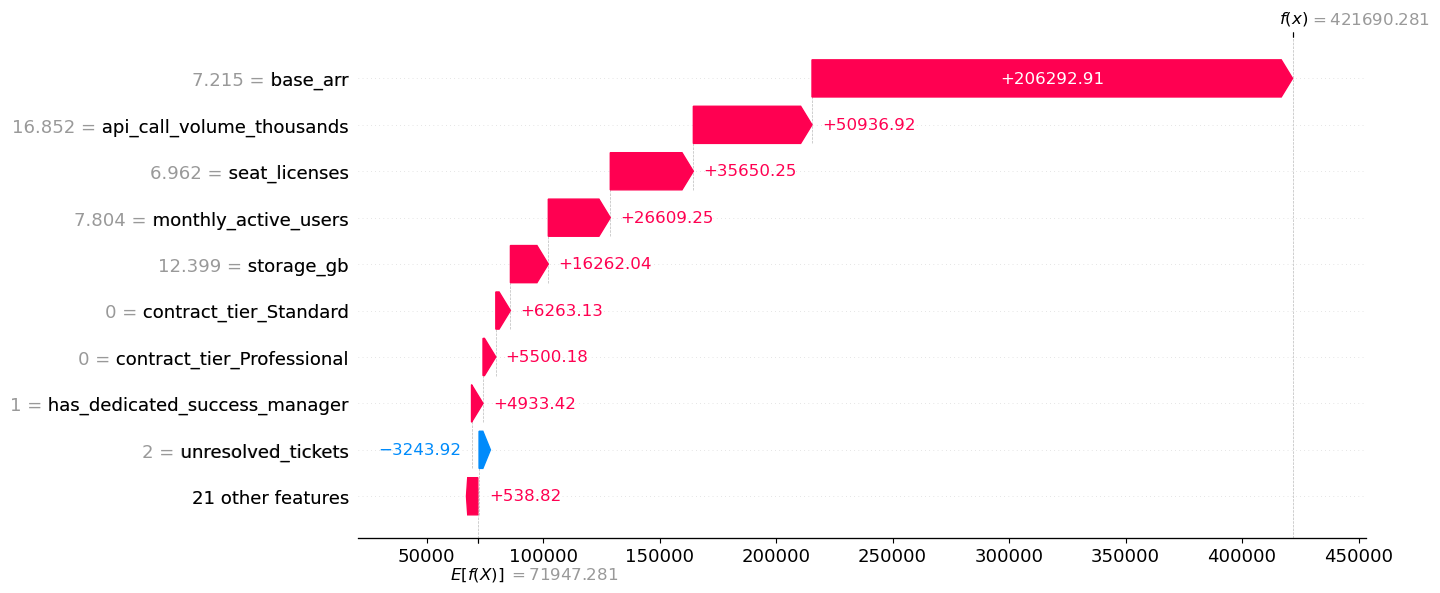

In [11]:
# Local Waterfall Forensics for Highest Predicted Account
shap.plots.waterfall(shap_values[max_idx], max_display=10, show=False)

fig = plt.gcf()
fig.set_size_inches(13, 6.5)

# Expand xmin by 45,000 so the negative unresolved_tickets arrow does not collide with feature labels
xmin, xmax = fig.axes[0].get_xlim()
for ax in fig.axes:
    ax.set_xlim(xmin - 45000, xmax + 10000)

plt.show()

---
## 8. Production Model Serialization & Numerical Parity Verification
We serialize the production pipeline bundle (`preprocessor`, `model`, `encoded_features`) into `enterprise_clv_pipeline.joblib`.
We reload the artifact from disk and verify 6-decimal numerical parity against in-memory test predictions with `np.testing.assert_allclose`.

In [12]:
import joblib

artifacts = {
    'preprocessor': processor,
    'model': champion_model,
    'encoded_features': all_features
}

joblib.dump(artifacts, 'enterprise_clv_pipeline.joblib')
print('✅ Artifacts successfully serialized to enterprise_clv_pipeline.joblib')

✅ Artifacts successfully serialized to enterprise_clv_pipeline.joblib


In [13]:
# Reload and Verify 6-Decimal Numerical Parity
loaded_bundle = joblib.load('enterprise_clv_pipeline.joblib')
loaded_preprocessor = loaded_bundle['preprocessor']
feature_names = loaded_bundle['encoded_features']
loaded_model = loaded_bundle['model']

reloaded_preds = loaded_model.predict(X_test_df)

np.testing.assert_allclose(y_test_pred, reloaded_preds, rtol=1e-15)
print('✅ 6-Decimal Numerical Parity Verified: Reloaded pipeline predictions match memory predictions perfectly!')

✅ 6-Decimal Numerical Parity Verified: Reloaded pipeline predictions match memory predictions perfectly!


---
## 9. Technical Governance & Production Engineering Findings

### 💡 Algorithmic Trade-offs & Production Forensics:
1. **Lasso ($L_1$) vs. XGBoost Trade-off:**
   * On pure global error, Lasso achieved competitive scores ($R^2 = 0.9947$, $\text{MAE} = \$4,325$, $\text{RMSE} = \$6,153$) because `base_arr` serves as a dominant linear anchor.
   * However, `XGBRegressor` was selected as the production champion because it achieved superior relative calibration across small and mid-tier accounts (MAPE = 12.13% vs. Lasso's 13.52%) and unlocked game-theoretic non-linear tree attribution via `shap.TreeExplainer`.
2. **Decoupled Preprocessing Architecture for SHAP:**
   * Transforming features into an explicit design matrix (`X_train_df`, `X_test_df`) before training decouples feature transformations from model inference.
   * This guarantees that `shap.TreeExplainer` receives exact 2D numerical matrices with verified column headers, eliminating wrapper serialization ambiguities and ensuring 100% feature parity during Streamlit app serving.